# Sonnensystem

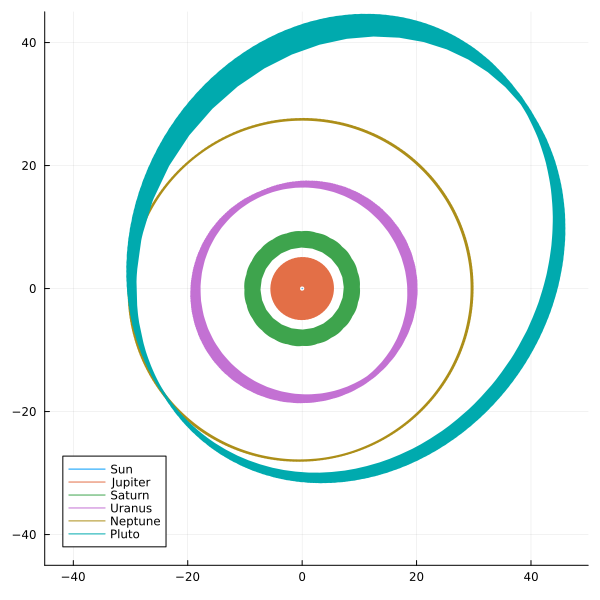

In diesem Projekt simulieren wir die Bewegung von Planeten unter dem Einfluss der Gravitation. Wir vergleichen dabei drei Zeitintegrationsverfahren – das *explizite Euler-Verfahren*, das *Störmer–Verlet-Verfahren* und die *implicit midpoint rule* – und untersuchen, wie gut sie die Erhaltungsgrößen Energie und Drehimpuls erhalten. Zuerst betrachten wir nur Jupiter (die Sonne bleibt fixiert), danach das gesamte äußere Sonnensystem.

## Die Bewegungsgleichungen

Nach Newton gilt für $N$ Körper mit Massen $m_i$ und Positionen $q_i(t) \in \mathbb{R}^3$
$$
\ddot q_i = \sum_{j \neq i} G\, m_j \, \frac{q_j - q_i}{\| q_j - q_i \|^3} .
$$
Mit den Geschwindigkeiten $v_i = \dot q_i$ wird daraus eine ODE erster Ordnung (hier sind alle Körper in $q$ und $v$ zusammengefasst):

<div class="alert alert-info" role="alert">

$$
\begin{equation}
\dot q = v, \qquad \dot v = a(q)
\end{equation}
$$

</div>

wobei $a(q)$ die Beschleunigung ist. Wir verwenden die Einheiten **AU** (Länge), **Sonnenmassen** (Masse) und **Tage** (Zeit). In diesen Einheiten ist die Gravitationskonstante $G = 2.95912208286 \cdot 10^{-4}$.

## Teil 1: Jupiter und die (fixierte) Sonne

Wir beginnen mit dem einfachsten Fall: Die Sonne sitzt fest im Ursprung und Jupiter bewegt sich in ihrem Gravitationsfeld. Dann ist $q \in \mathbb{R}^3$ die Position von Jupiter und
$$
a(q) = - GM \, \frac{q}{\|q\|^3}, \qquad GM = G\, m_{\text{Sonne}} .
$$
Dieses System hat zwei Erhaltungsgrößen (jeweils pro Masse von Jupiter): die *Energie* und den *Drehimpuls*
$$
E = \frac{1}{2}\|v\|^2 - \frac{GM}{\|q\|}, \qquad L = q \times v .
$$

Folgende Konstanten und Anfangsbedingungen für Jupiter (Einheiten: AU und AU/Tag) sind gegeben:

In [32]:
using LinearAlgebra
using Plots

const G = 2.95912208286e-4     # Gravitationskonstante in AU^3 / (M_sun * Tag^2)
const m_sun = 1.00000597682    # Masse der Sonne in M_sun (inklusive der inneren Planeten)
const GM = G * m_sun

q_jup = [-3.5023653, -3.8169847, -1.5507963]       # Position von Jupiter
v_jup = [0.00565429, -0.00412490, -0.00190589]     # Geschwindigkeit von Jupiter

3-element Vector{Float64}:
  0.00565429
 -0.0041249
 -0.00190589

<div class="alert alert-success" role="alert">

Implementiere die Beschleunigung eines Körpers im Feld der fixierten Sonne
```julia
raw"""
computes the acceleration a(q) = -GM q / |q|^3 of a body at position q (3-vector)
in the field of a fixed sun at the origin
"""
function acceleration_fixed_sun(q, GM)
    ...
end
```
sowie die beiden Erhaltungsgrößen
```julia
energy_fixed_sun(q, v, GM)     # E = |v|^2 / 2 - GM / |q|
angular_momentum(q, v)         # L = q x v
```

</div>

**Tipp**

`LinearAlgebra` implementiert `norm`, `dot` und `cross`.

<div class="alert alert-success" role="alert">

Implementiere einen einzelnen Zeitschritt vom expliziten Eulerverfahren
```julia
raw"""
computes (q_{n+1}, v_{n+1}) from (q_n, v_n) using the explicit Euler method
acc: function that computes the acceleration, a = acc(q)
h: time-step size
"""
function euler_step(acc, q, v, h)
    ...
    return q_new, v_new
end
```
und eine Funktion, die die Zeitentwicklung berechnet
```julia
raw"""
time-evolves the state (q_0, v_0).
step: function that evolves the state a single time step: q_new, v_new = step(acc, q, v, h)
acc: function that computes the acceleration, a = acc(q)
h: time-step size
N_steps: number of time steps

returns the times t_n and the computed states q_n and v_n (as vectors of states) including the initial_state
"""
function integrate(step, acc, q_0, v_0, h, N_steps)
    ...
end
```
Die Funktion soll die Zeiten $t_n$ sowie $q_n$ und $v_n$ für alle Zeitschritte zurückgeben.

</div>

**Tipp**
Die Funktion `integrate` soll später auch mit Matrizen als Zustand funktionieren; schreibt sie also nicht nur für 3-Vektoren.

<div class="alert alert-success" role="alert">

Berechne die Umlaufperiode von Jupiter. Aus der Energie folgt die große Halbachse $a = -GM/(2E)$ und damit
$$
T = 2\pi \sqrt{a^3 / GM} .
$$
Simuliere mit dem expliziten Eulerverfahren $10$ Umläufe von Jupiter mit $100$ Zeitschritten pro Umlauf (`h = T/100`, `N_steps = 1000`).

Plotte
* die Bahn von Jupiter in der $x$-$y$-Ebene,
* den relativen Energiefehler $|E_n - E_0| / |E_0|$ als Funktion der Zeit,
* den relativen Drehimpulsfehler $\|L_n - L_0\| / \|L_0\|$ als Funktion der Zeit

Kommentiert die Plots.

</div>

Das *Störmer–Verlet-Verfahren* (auch *Leapfrog* genannt) berechnet einen Zeitschritt in drei Teilschritten:
$$
\begin{aligned}
v_{n+1/2} &= v_n + \frac{h}{2}\, a(q_n), \\
q_{n+1} &= q_n + h\, v_{n+1/2}, \\
v_{n+1} &= v_{n+1/2} + \frac{h}{2}\, a(q_{n+1}) .
\end{aligned}
$$

<div class="alert alert-success" role="alert">

Implementiere einen einzelnen Zeitschritt vom Störmer–Verlet-Verfahren
```julia
function verlet_step(acc, q, v, h)
    ...
    return q_new, v_new
end
```
Wiederhole die Simulation aus der vorigen Aufgabe mit `verlet_step` (gleiche Parameter) und plotte die Fehler gemeinsam mit denen vom Eulerverfahren. Vergleicht die beiden Verfahren.

</div>

**Tipp**
Um die Fehler der Energie und vom Drehimpuls ordentlich zu vergleichen müsst ihr die `y`-Akse logarithmisch machen. Achtet dabei darauf, exsakte Nullen vorher zu filtern! (z.B. mit `clip(x)= max(x,1e-16)`)

## Teil 2: Implicit Midpoint Rule
Bei der *implicit midpoint rule* ist der Zeitschritt für $\dot q = v$, $\dot v = a(q)$ durch
$$
\begin{aligned}
v_{n+1} &= v_n + h\, a(\bar q), \\
q_{n+1} &= q_n + h\, \frac{v_n + v_{n+1}}{2},
\end{aligned}
\qquad \bar q := \frac{q_n + q_{n+1}}{2}
$$
gegeben. Das ist ein *nichtlineares* Gleichungssystem für $(q_{n+1}, v_{n+1})$. Wie beim Pendel können wir die Geschwindigkeit eliminieren (setze die erste Gleichung in die zweite ein) und erhalten **eine** Gleichung für **eine** Unbekannte $q_{n+1}$.

$$
0 = F(q_{n+1}) = q_{n+1} - q_n - h\, v_n - \frac{h^2}{2}\, a\!\left( \frac{q_n + q_{n+1}}{2} \right) .
$$


<div class="alert alert-success" role="alert">

Löse $F(q_{n+1}) = 0$ mit dem Newton-Verfahren. Beim Pendel hattet ihr eine Unbekannte, $x \leftarrow x - F(x)/F'(x)$. Hier ist $F : \mathbb{R}^3 \to \mathbb{R}^3$, und aus $F'$ wird die *Jacobi-Matrix* $J_F$ (eine $3\times 3$-Matrix). Die Division durch $F'$ wird zum Lösen eines linearen Gleichungssystems:
$$
q_{n+1} \leftarrow q_{n+1} - \delta, \qquad J_F\, \delta = F(q_{n+1}) .
$$
Für die Jacobi-Matrix von $F$ gilt (Kettenregel! $\partial \bar q / \partial q_{n+1} = 1/2$)
$$
J_F = 1 - \frac{h^2}{4} \, \frac{\partial a}{\partial q}(\bar q) .
$$
Die Matrix $\frac{\partial a}{\partial q}$ ist für unser Problem unten gegeben (`jacobian_fixed_sun`).

Implementiere damit einen einzelnen Zeitschritt der implicit midpoint rule
```julia
raw"""
computes (q_{n+1}, v_{n+1}) from (q_n, v_n) using the implicit midpoint rule,
solving the nonlinear equation for q_{n+1} with Newton's method.
acc: function that computes the acceleration, a = acc(q)
jac: function that computes the Jacobian of the acceleration, da/dq = jac(q)
"""
function implicit_midpoint_step(acc, jac, q, v, h)
    ...
    return q_new, v_new
end
```

</div>



In [37]:
# Jacobi-Matrix (3x3) der Beschleunigung a(q) = -GM q/|q|^3  (gegeben)
function jacobian_fixed_sun(q, GM)
    r = norm(q)
    return -GM * (I / r^3 - 3 * q * q' / r^5)
end



jacobian_fixed_sun (generic function with 1 method)

**Hints**
* Wählt als Startwert für Newton den Schritt vom expliziten Euler-Verfahren, $q_{n+1}^{(0)} = q_n + h\, v_n$.
* Brecht ab, sobald $\|\delta\|_\infty$ kleiner als etwa `1e-13` ist, und begrenzt die Anzahl der Iterationen (z.B. auf 20).
* Das lineare System löst man schneller mit `J \ F` (und nicht mit `inv(J) * F`).
* $a$ und $\partial a/\partial q$ müssen am **Mittelpunkt** $\bar q$ ausgewertet werden, nicht bei $q_{n+1}$ oder $q_n$.
* `integrate` erwartet einen Schritt der Form `step(acc, q, v, h)`. Mit einer anonymen Funktion passt `implicit_midpoint_step`:
```julia
jac = q -> jacobian_fixed_sun(q, GM)
midpoint_step = (acc, q, v, h) -> implicit_midpoint_step(acc, jac, q, v, h)
```
* Ihr könnt eure Implementierung testen, indem ihr den Residuenvektor $F(q_{n+1})$ nach Ende der Iteration ausgebt.

<div class="alert alert-success" role="alert">

Simuliere Jupiter nun mit allen drei Verfahren (gleiche Parameter wie oben) und plotte
* die Bahnen,
* den relativen Energiefehler,
* den relativen Drehimpulsfehler

für alle drei Verfahren in jeweils einem gemeinsamen Plot.
</div>

<div class="alert alert-success" role="alert">

Bestimme die *Konvergenzordnung* der drei Verfahren. Simuliere dazu genau einen Umlauf ($t = T$) mit $n$ Zeitschritten, also `h = T/n`, für
`n = [100, 200, 400, 800, 1600, 3200]` und berechne den Positionsfehler $\|q_n - q_{\text{ref}}\|$ am Ende. Als Referenzlösung $q_{\text{ref}}$ verwendet ihr Störmer–Verlet mit sehr vielen Schritten (z.B. $n = 51200$).

Plotte die Fehler als Funktion von `h` doppelt-logarithmisch (`xscale = :log10, yscale = :log10`). Plottet im gleichen Plot die Linien
$$
y_{1}(h) = a_1  h  \\ 
y_{2}(h) = a_2 h^2
$$
für passende Konstanten $a_1, a_2$ sodass ihr die Steigungen der Fehler mit $y_1$ $ y_2$ vergleichen könnt. Was sieht ihr?
</div>

**Tipps**

1. Berechnet die Referenzlösung einmal und vergleicht nur das Endresultat: `q_t[end]`

## Teil 3: Das äußere Sonnensystem

Jetzt betrachten wir die Sonne, Jupiter, Saturn, Uranus, Neptun und Pluto (die inneren Planeten sind in der Masse der Sonne enthalten) – und die Sonne darf sich auch bewegen. Der Zustand ist jetzt eine $3 \times N$-Matrix $q$ (und $v$), wobei jede *Spalte* ein Körper ist. Die Anfangsdaten stammen aus dem Buch *Geometric Numerical Integration* von Hairer, Lubich und Wanner (Kap. I.2.4) und sind unten gegeben.

Die Beschleunigung von Körper $i$ ist
$$
a_i = \sum_{j \neq i} G\, m_j\, \frac{q_j - q_i}{\|q_j - q_i\|^3},
$$
die Gesamtenergie und der Gesamtdrehimpuls sind
$$
E = \sum_i \frac{1}{2} m_i \|v_i\|^2 - \sum_{i<j} \frac{G\, m_i m_j}{\|q_i - q_j\|}, \qquad L = \sum_i m_i\, q_i \times v_i .
$$

In [41]:
# Anfangsdaten (gegeben). Rückgabe: Namen, Massen m (Länge N), Positionen q (3 x N), Geschwindigkeiten v (3 x N)
function outer_solar_system()
    names = ["Sun", "Jupiter", "Saturn", "Uranus", "Neptune", "Pluto"]
    m = [1.00000597682, 0.000954786104043, 0.000285583733151,
         0.0000437273164546, 0.0000517759138449, 1 / 1.3e8]
    q = [0.0 -3.5023653 9.0755314 8.3101420 11.4707666 -15.5387357 ;
         0.0 -3.8169847 -3.0458353 -16.2901086 -25.7294829 -25.2225594 ;
         0.0 -1.5507963 -1.6483708 -7.2521278 -10.8169456 -3.1902382]
    v = [0.0 0.00565429 0.00168318 0.00354178 0.00288930 0.00276725 ;
         0.0 -0.00412490 0.00483525 0.00137102 0.00114527 -0.00170702 ;
         0.0 -0.00190589 0.00192462 0.00055029 0.00039677 -0.00136504]
    return names, m, q, v
end

outer_solar_system (generic function with 1 method)

<div class="alert alert-success" role="alert">

In den gegebenen Daten ruht die Sonne, der Schwerpunkt des Systems bewegt sich aber. Schreibe eine Funktion
```julia
raw"""
shifts positions q and velocities v (3 x N matrices) in place, such that the center of mass Q = sum_i m_i q_i / sum_i m_i is at the origin and the total momentum sum_i m_i v_i is zero
"""
function to_barycentre!(q, v, m)
    ...
end
```
Die Funktion soll die Positionen und Geschwindigkeiten **in-place** transformieren:
$$
q_i \to q_i - Q \\
v_i \to v_i - V
$$
wobei $Q =  \frac{1}{M} \sum_{i} m_i q_i ,  V = \frac{1}{M} \sum_i m_i v_i$ und $M = \sum_i m_i$



Transformiere die Anfangsdaten in dieses Koordinatensystem.
</div>

In [42]:
function to_barycentre!(q, v, m)
    M = sum(m)
    Q = q * m/M
    V = v * m/M
    q .-= Q
    v .-= V
    return q, v
end

names, m, q0, v0 = outer_solar_system()
to_barycentre!(q0, v0, m)

([-0.00020470982987891035 -3.502570009829879 … 11.47056189017012 -15.538940409829879; 0.006550139855052495 -3.810434560144947 … -25.72293276014495 -25.21600926014495; 0.002824833990245127 -1.547971466009755 … -10.814120766009756 -3.187413366009755], [-6.17552963622584e-6 0.005648114470363774 … 0.0028831244703637743 0.0027610744703637745; 2.43502570182194e-6 -0.004122464974298178 … 0.0011477050257018221 -0.001704584974298178; 1.2238395709323683e-6 -0.0019046661604290676 … 0.0003979938395709324 -0.0013638161604290677])

<div class="alert alert-success" role="alert">

Implementiere die Funktionen
```julia
acceleration_nbody(q, m)           # returns a 3 x N matrix with the accelerations a_i
energy_nbody(q, v, m)              # total energy E
angular_momentum_nbody(q, v, m)    # total angular momentum L (3-vector)
```
Testet `acceleration_nbody`: Nach dem dritten Newtonschen Gesetz muss $\sum_i m_i a_i = 0$ gelten.

</div>

**Hints**
* Zwei verschachtelte Schleifen über $i$ und $j$ (`for i in 1:N, j in 1:N`) reichen aus. Mit `i == j && continue` überspringt man die Selbstwechselwirkung.

In [43]:
function acceleration_nbody(q, m)
    N = length(m)
    a = zeros(3, N)
    for i in 1:N, j in 1:N
        i == j && continue
        d = q[:, j] - q[:, i]
        a[:, i] += G * m[j] * d / norm(d)^3
    end
    return a
end

function energy_nbody(q, v, m)
    N = length(m)
    E = 0.0
    for i in 1:N
        E += 0.5 * m[i] * dot(v[:, i], v[:, i])
        for j in i+1:N
            E -= G * m[i] * m[j] / norm(q[:, i] - q[:, j])
        end
    end
    return E
end

function angular_momentum_nbody(q, v, m)
    L = zeros(3)
    for i in eachindex(m)
        L += m[i] * cross(q[:, i], v[:, i])
    end
    return L
end

norm(acceleration_nbody(q0, m) * m)

1.3974511994897761e-24

<div class="alert alert-success" role="alert">

Simuliere das äußere Sonnensystem für $2000$ Zeitschritte mit `h = 100` Tagen mit dem **expliziten Eulerverfahren** und mit **Störmer–Verlet**. Plotte
* die Bahnen aller Körper in der $x$-$y$-Ebene,
* den relativen Energiefehler und
* den relativen Fehler vom Gesamtdrehimpuls

als Funktion der Zeit für beide Verfahren

</div>

**Tipp**

Beim expliziten Eulerverfahren fliegen die Planeten weit aus dem Bild. Begrenzt die Achsen eurer Bahnplots mit `xlims = (-50, 50)`, `ylims = (-50, 50)`.

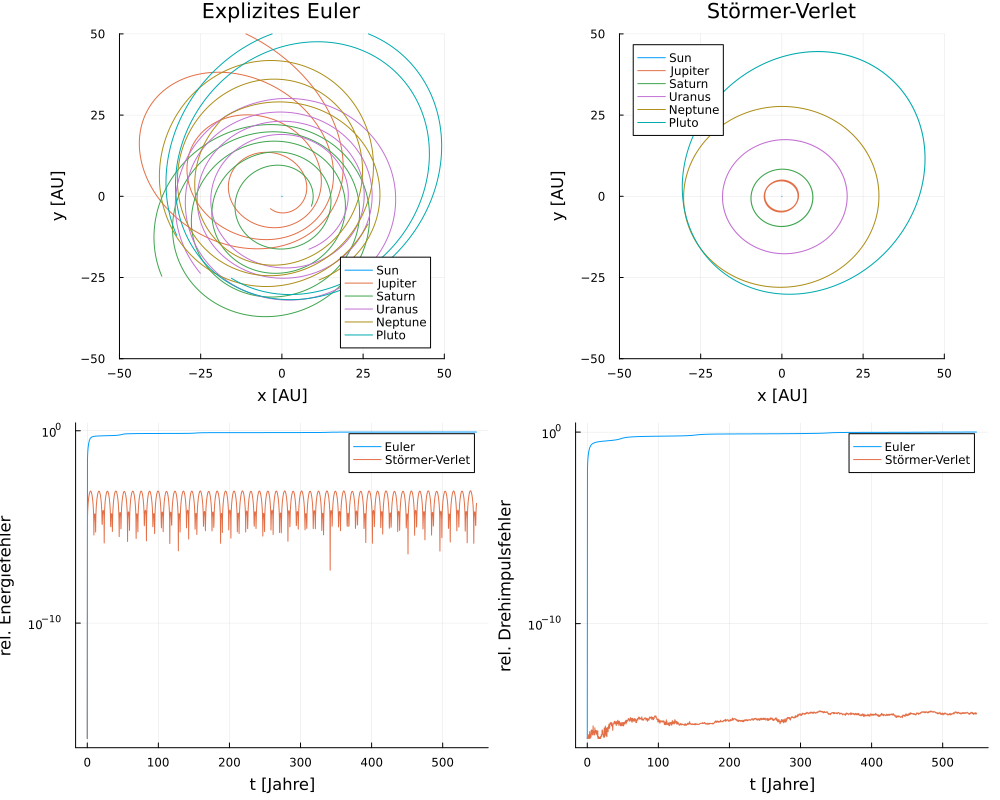

In [44]:
acc = q -> acceleration_nbody(q, m)
h = 100.0
N_steps = 2000

t_e, q_e, v_e = integrate(euler_step,  acc, q0, v0, h, N_steps)
t_v, q_v, v_v = integrate(verlet_step, acc, q0, v0, h, N_steps)

clip(x) = max(x, 1e-16)

function relative_errors(qs, vs, m)
    E = [energy_nbody(q, v, m) for (q, v) in zip(qs, vs)]
    L = [angular_momentum_nbody(q, v, m) for (q, v) in zip(qs, vs)]
    errE = abs.(E .- E[1]) ./ abs(E[1])
    errL = [norm(l - L[1]) / norm(L[1]) for l in L]
    return errE, errL
end

errE_e, errL_e = relative_errors(q_e, v_e, m)
errE_v, errL_v = relative_errors(q_v, v_v, m)

function plot_orbits(qs, names; title = "")
    p = plot(; xlims = (-50, 50), ylims = (-50, 50), aspect_ratio = :equal,
             xlabel = "x [AU]", ylabel = "y [AU]", title = title)
    for i in eachindex(names)
        plot!(p, [q[1, i] for q in qs], [q[2, i] for q in qs]; label = names[i])
    end
    return p
end

p1 = plot_orbits(q_e, names; title = "Explizites Euler")
p2 = plot_orbits(q_v, names; title = "Störmer-Verlet")

p3 = plot(t_e ./ 365.25, clip.(errE_e), yscale = :log10, label = "Euler",
          xlabel = "t [Jahre]", ylabel = "rel. Energiefehler")
plot!(p3, t_v ./ 365.25, clip.(errE_v), label = "Störmer-Verlet")

p4 = plot(t_e ./ 365.25, clip.(errL_e), yscale = :log10, label = "Euler",
          xlabel = "t [Jahre]", ylabel = "rel. Drehimpulsfehler")
plot!(p4, t_v ./ 365.25, clip.(errL_v), label = "Störmer-Verlet")

plot(p1, p2, p3, p4, layout = (2, 2), size = (1000, 800))